# Monitoring hydrologic water quality in pasturelands through spatial overlay analysis

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc">
    <ul class="toc-item">
    <li><span><a href="#Introduction" data-toc-modified-id="Introduction-1">Introduction</a></span></li>
    <li><span><a href="#Workflow" data-toc-modified-id="Workflow-1">Workflow</a></span></li>
    <li><span><a href="#Necessary-Imports" data-toc-modified-id="Necessary-Imports-2">Necessary Imports</a></span></li>
    <li><span><a href="#Connect-to-your-GIS" data-toc-modified-id="Connect-to-your-GIS-3">Connect to your GIS</a></span></li>
    <li><span><a href="#Get-data-for-analysis" data-toc-modified-id="Get-data-for-analysis-4">Get data for analysis</a></span></li>
    <li><span><a href="#Assigning-basin-information-to-allotments" data-toc-modified-id="Assigning-basin-information-to-allotments-5">Assigning basin information to allotments</a></span></li>
    <ul class="tocSkip">
        <li><span><a href="#Mapping-and-exploring-basin-overlay-results" data-toc-modified-id="Mapping-and-exploring-basin-overlay-results-5.1">Mapping and exploring basin overlay results</a></span></li>
        <li><span><a href="#Display-grazing-allotments-within-a-particular-basin" data-toc-modified-id="Display-grazing-allotments-within-a-particular-basin-5.2">Display grazing allotments within a particular basin</a></span></li>
        <li><span><a href="#Display-a-particular-grazing-allotment-to-see-which-basins-intersect-it" data-toc-modified-id="Display-a-particular-grazing-allotment-to-see-which-basins-intersect-it-5.3">Display a particular grazing allotment to see which basins intersect it</a></span></li>
    </ul>
    <li><span><a href="#Assigning-allotment-information-to-streams" data-toc-modified-id="Assigning-allotment-information-to-streams-6">Assigning allotment information to streams</a></span></li>
    <ul>
        <li><span><a href="#Mapping-and-searching-stream-overlay-results" data-toc-modified-id="Mapping-and-searching-stream-overlay-results-6.1">Mapping and searching stream overlay results</a></span></li>
        <li><span><a href="#Display-a-stream-and-grazing-allotments-it-intersects" data-toc-modified-id="Display-a-stream-and-grazing-allotments-it-intersects-6.2">Display a stream and grazing allotments it intersects</a></span></li>
    </ul>
    <li>
        <span><a href="#Conclusion" data-toc-modified-id="Conclusion-7">Conclusion</a></span></li>
    </ul>
</div>

### Introduction

Much of the grazing in the state of Oregon occurs on federal lands. Grazing areas are divided into allotments by federal agencies. They issue permits or leases to ranchers for individual grazing allotments.

Studies by the state of Oregon Department of Environment Quality (DEQ) indicate that streams located in grazing areas are majorly polluted by sediments and animal waste. This is a substantial concern as it causes degradation of water quality, threatening human and ecological health. The department thus wants to inspect the effect of livestock grazing on the state’s water quality.

While federal agencies manage the grazing lands by allotments, the state's biologists monitor water quality by watersheds, or hydrologic basins (as the hydrologists refer to them). If a basin has water quality issues, then biologists who monitor water quality for watersheds or hydrologic basins could identify all grazing allotments that are in that basin. They can then work with federal agencies who manages the grazing allotments to ensure that permit holders are conforming to best practices.

<img src="data:image/PNG; base64, ...">

<center>Grazing allotments and hydrologic basin boundaries. Many allotments fall in more than one hydrologic basin.</center>

Since grazing allotments were not created with basin boundaries in mind,  an allotment can fall completely within a hydrologic basin, or can cross basin boundaries, falling in two or more basins.

This sample uses ArcGIS API for Python to find out which watershed, or watersheds, each grazing allotment falls in, for water quality monitoring. 

It demonstrates using tools such as `overlay_layers` to identify  allotments in a particular basin. This will assign each allotment to the hydrologic basins it falls within.

Moreover, in order to successfully identify the source of pollution in each basin, each basin is assigned the grazing allotment name and the number of streams within. This will help identify which allotment each segment of each stream passes through. If field tests find a water quality issue with a particular stream, biologists can link back to the federal database and get a report on each suspect allotment (the type and number of livestock, the owner information, the administrating office, and so on). The information will help them determine the source of pollution.

### Workflow

<img src="data:image/PNG; base64, ...">

### Necessary Imports

In [1]:
%matplotlib inline

import pandas as pd
pd.set_option('mode.chained_assignment', None)
import matplotlib.pyplot as plt
from IPython.display import display
from datetime import datetime as dt

from arcgis.gis import GIS
from arcgis.features.manage_data import overlay_layers

### Connect to your GIS

Connect to our GIS via an existing profile or creating a new connection by e.g. gis = GIS("https://www.arcgis.com", "arcgis_python", "P@ssword123")

In [2]:
gis = GIS('home')

### Get data for analysis

Search for **grazing allotments and watersheds** layer in ArcGIS Online.

In [3]:
items = gis.content.search('grazing allotments and watersheds owner:api_data_owner', item_type = 'Feature Layer Collection', outside_org=True)
items

[<Item title:"grazing allotments and watersheds" type:Feature Layer Collection owner:api_data_owner>]

The code below displays the items.

<Item title:"grazing allotments and watersheds" type:Feature Layer Collection owner:api_data_owner>
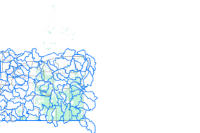

In [4]:
for item in items:
    display(item)

We will use the first item for our analysis. Since the item is a Feature Layer Collection, accessing the layers property will give us a list of FeatureLayer objects.

In [5]:
data = items[0]

The code below cycles through the layers and prints their names.

In [6]:
for lyr in data.layers:
    print(lyr.properties.name)

hydro_units
counties
grazing_allotments
streams


Let us now get the layers and assign a variable to them.

In [7]:
hydro_units = data.layers[0]

In [8]:
counties = data.layers[1]

In [9]:
grazing_allotments = data.layers[2]

In [10]:
streams = data.layers[3]

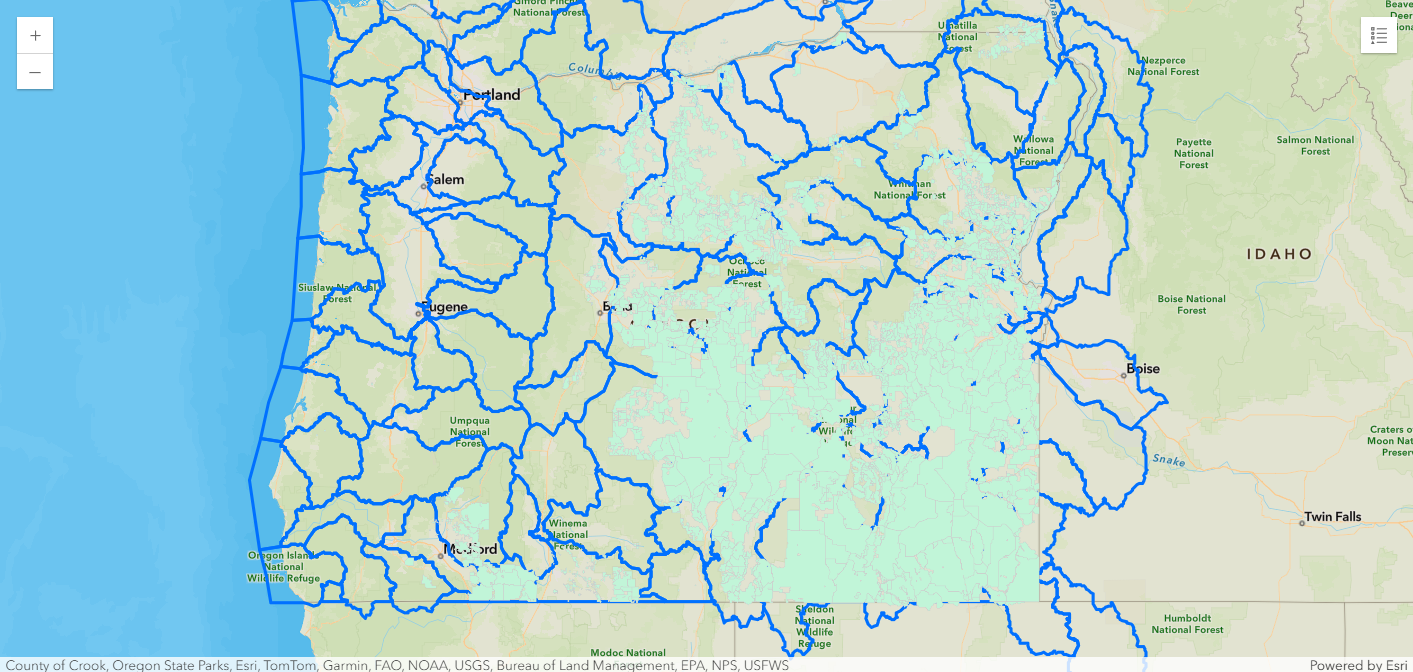

In [11]:
map1 = gis.map("Oregon")
map1.legend.enabled = True
map1

#### Visualize the list of basemaps available

In [12]:
map1.content.add(hydro_units)
map1.content.add(grazing_allotments)

In [13]:
map1.zoom_to_layer(hydro_units)

### Assigning basin information to allotments

In order to find out which hydrologic basins each grazing allotment is in, we will use `overlay_layers` tool. It combines two layers, an analysis layer and an overlay layer, into a new layer, creating new features and combining attributes from the two layers according to the overlay method selected. Overlay operations supported are Intersect, Union, and Erase.

We will overlay grazing allotments with hydrologic basins using the Intersect option.

In [14]:
basin_overlay = overlay_layers(grazing_allotments,
                               hydro_units,
                               overlay_type='Intersect',
                               output_name="OverlayAllotmentWithBasin" + str(dt.now().microsecond))

{"cost": 1.988}


In [15]:
basin_overlay

<Item title:"OverlayAllotmentWithBasin681003" type:Feature Layer Collection owner:arcgis_python>

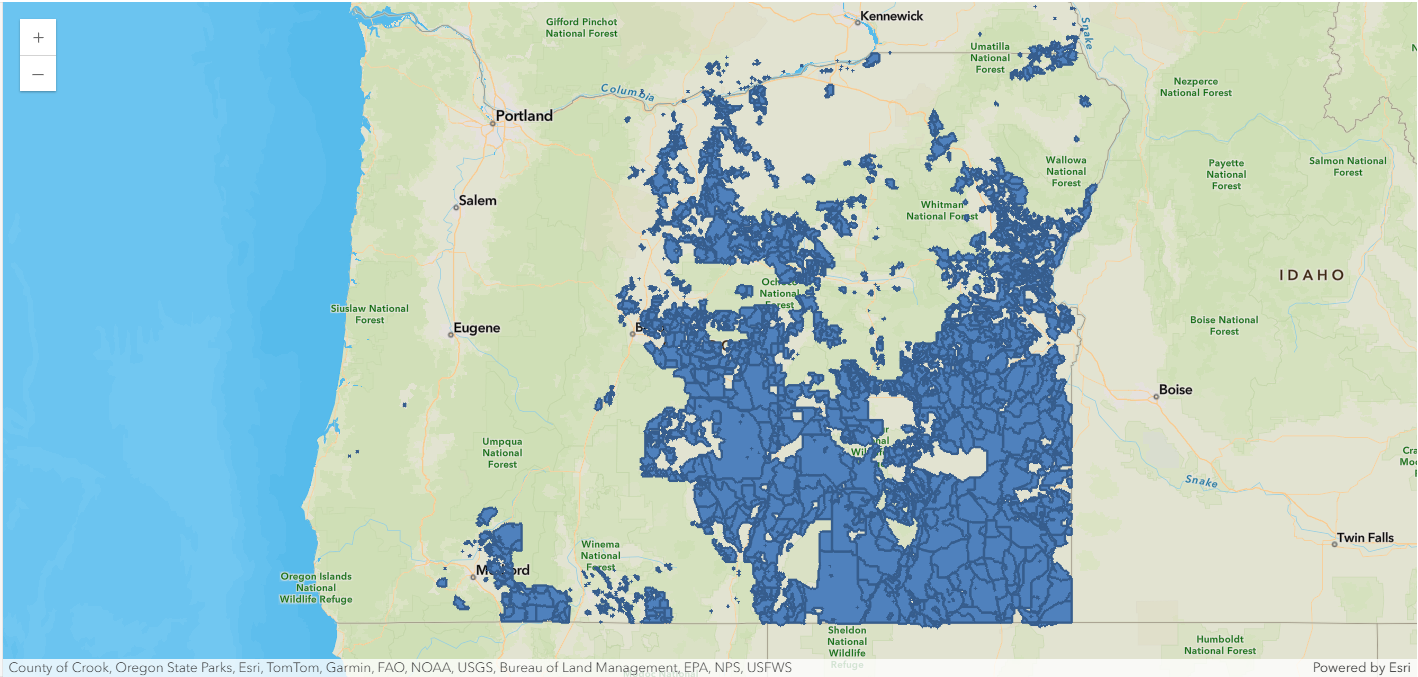

In [16]:
map2 = gis.map('Oregon')
map2

In [17]:
map2.content.add(basin_overlay.layers[0])

The new features have all the attributes of the features in the input layers. In this case, the new allotment features are assigned the attributes-including the name and ID-of the hydrologic basin they fall within. Allotments that fall in two or more basins are split at the basin boundaries and the corresponding attributes assigned to each portion of the allotment.



### Mapping and exploring basin overlay results

We will explore overlay results using both matplotlib and plot method of Spatially Enabled Dataframe.

Let's read the overlay layer as Spatially Enabled DataFrame.

In [18]:
sdf = pd.DataFrame.spatial.from_layer(basin_overlay.layers[0])

In [19]:
slctd_cols = ['BASIN_NAME', 'allot_name', 'allot_no', 'REGION', 'HUC', 'SHAPE']

In [20]:
basin_overlay_df = sdf[slctd_cols]

In [21]:
basin_overlay_df.head()

,BASIN_NAME,allot_name,allot_no,REGION,HUC,SHAPE
0,LOST,FLESHER,00820,18,18010204,"{""rings"": [[[-13527204.1134, 5168951.5729], [-..."
1,UPPER ROGUE,LAKE CREEK SUMMER,10122,17,17100307,"{""rings"": [[[-13645693.1151, 5212303.7991], [-..."
2,MIDDLE ROGUE,COVE RANCH,10143,17,17100308,"{""rings"": [[[-13642411.7923, 5193214.6468], [-..."
3,LOWER DESCHUTES,FERRY CANYON COMMON,07547,17,17070306,"{""rings"": [[[-13456899.9442, 5683017.9365], [-..."
4,UPPER ROGUE,DEVON SOUTH,10043,17,17100307,"{""rings"": [[[-13656539.5774, 5225486.2911], [-..."


We will group the dataframe by 'BASIN_NAME'. To get the number of basins in each group we will use the [size()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.core.groupby.GroupBy.size.html) method. 

In [22]:
grp_basin = basin_overlay_df.groupby('BASIN_NAME').size()

In [23]:
grp_basin.head()

BASIN_NAME
ALVORD LAKE           51
APPLEGATE              2
BEAVER-SOUTH FORK     52
BROWNLEE RESERVOIR    52
BULLY                 29
dtype: int64

In [24]:
grp_basin.nlargest(10)

BASIN_NAME
POWDER                  156
BURNT                   146
LOWER JOHN DAY          128
UPPER MALHEUR           122
LOST                     84
LOWER CROOKED            72
HARNEY-MALHEUR LAKES     71
SUMMER LAKE              69
UPPER CROOKED            65
WILLOW                   62
dtype: int64

<AxesSubplot: ylabel='BASIN_NAME'>

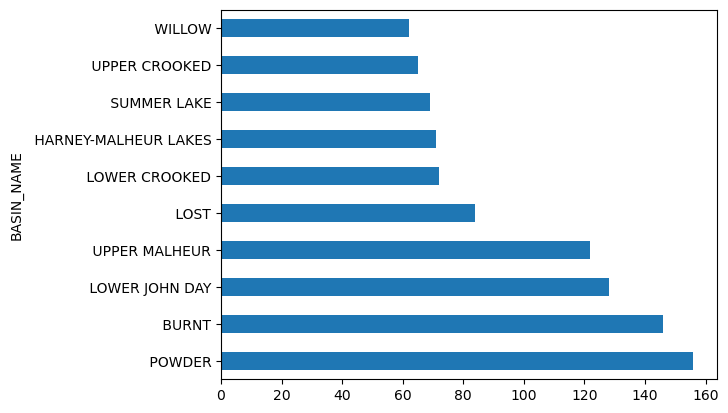

In [25]:
grp_basin.nlargest(10).plot(kind='barh')

We see that Powder Basin intersected the largest number of grazing allotments, followed by Burnt and Lower John Day basins.

We will now map grazing allotments by hydrologic basin.

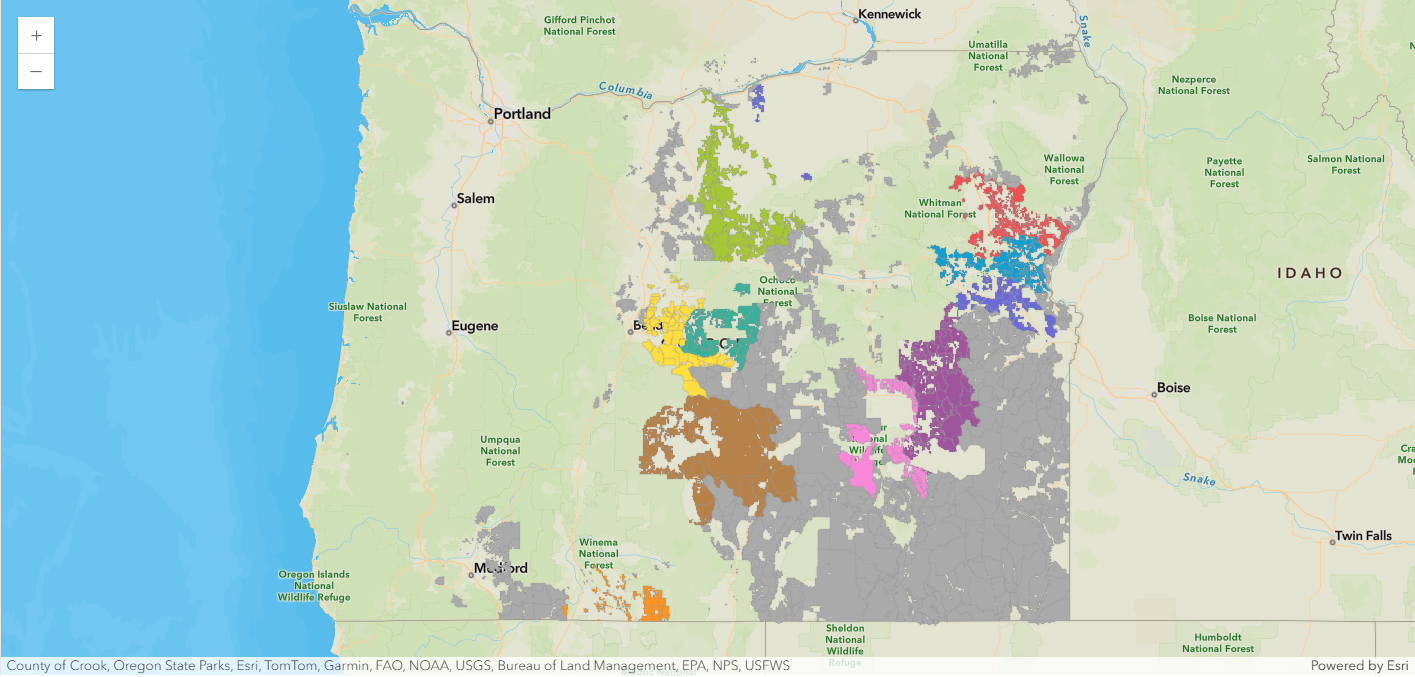

In [26]:
map3 = gis.map('oregon')
map3.content.add(basin_overlay_df)
map3

<center>Grazing allotments are color coded by the basin they are in. Allotment features are split where a basin boundary crosses them. Selecting an allotment feature displays the allotment and basin information--the basin information is associated with the feature.</center>

In [27]:
sm_manager = map3.content.renderer(0).smart_mapping()
sm_manager.unique_values_renderer(field="BASIN_NAME")

### Display grazing allotments within a particular basin

Let's get a list of all basin names.

In [28]:
basin_overlay_df.BASIN_NAME.str.strip().unique()

<StringArray>
[                        'LOST',                  'UPPER ROGUE',
                 'MIDDLE ROGUE',              'LOWER DESCHUTES',
                       'UMPQUA',               'UPPER JOHN DAY',
           'UPPER KLAMATH LAKE',                      'SILVIES',
             'LITTLE DESCHUTES',          'NORTH FORK JOHN DAY',
              'UPPER DESCHUTES',                 'SOUTH UMPQUA',
               'LOWER JOHN DAY',                       'WILLOW',
         'MIDDLE COLUMBIA-HOOD',                'UPPER KLAMATH',
                     'COQUILLE',                        'TROUT',
         'MIDDLE FORK JOHN DAY',                    'APPLEGATE',
 'MIDDLE COLUMBIA-LAKE WALLULA',                        'BUTTE',
                      'SPRAGUE',            'BEAVER-SOUTH FORK',
                'UPPER CROOKED',                'LOWER CROOKED',
           'LOWER GRANDE RONDE',                       'IMNAHA',
                     'UMATILLA',           'UPPER GRANDE RONDE',
           

We will apply a filter to visualize grazing allotments within a particular basin.

In [29]:
john_day_df = basin_overlay_df[basin_overlay_df['BASIN_NAME'] == ' MIDDLE FORK JOHN DAY']

In [30]:
john_day_df

,BASIN_NAME,allot_name,allot_no,REGION,HUC,SHAPE
69,MIDDLE FORK JOHN DAY,NORTH FORK,04029,17,17070203,"{""rings"": [[[-13278826.6115, 5607309.3595], [-..."
166,MIDDLE FORK JOHN DAY,GIBSON CREEK,04135,17,17070203,"{""rings"": [[[-13263280.5074, 5602968.1923], [-..."
169,MIDDLE FORK JOHN DAY,MUD SPRINGS,04015,17,17070203,"{""rings"": [[[-13269728.7602, 5614038.7], [-132..."
186,MIDDLE FORK JOHN DAY,PASS CREEK,04184,17,17070203,"{""rings"": [[[-13268669.5057, 5592601.4069], [-..."
188,MIDDLE FORK JOHN DAY,SIDEHILL,04026,17,17070203,"{""rings"": [[[-13238795.622, 5579105.8225], [-1..."
261,MIDDLE FORK JOHN DAY,MIDDLE FORK,04014,17,17070203,"{""rings"": [[[-13234233.0817, 5586868.7282], [-..."
305,MIDDLE FORK JOHN DAY,JINKS CREEK,04050,17,17070203,"{""rings"": [[[-13282326.8528, 5597674.5336], [-..."
347,MIDDLE FORK JOHN DAY,DOHERTY P JOE SHEEP,04193,17,17070203,"{""rings"": [[[-13251986.3822, 5614102.6014], [-..."
513,MIDDLE FORK JOHN DAY,SLICKEAR MTN.,04003,17,17070203,"{""rings"": [[[-13269794.5899, 5593722.8408], [-..."
635,MIDDLE FORK JOHN DAY,WEST FORK BURNT RIVER,15324,17,17070203,"{""rings"": [[[-13170488.1642, 5557278.5571], [-..."


Let's plot the filtered results on map.

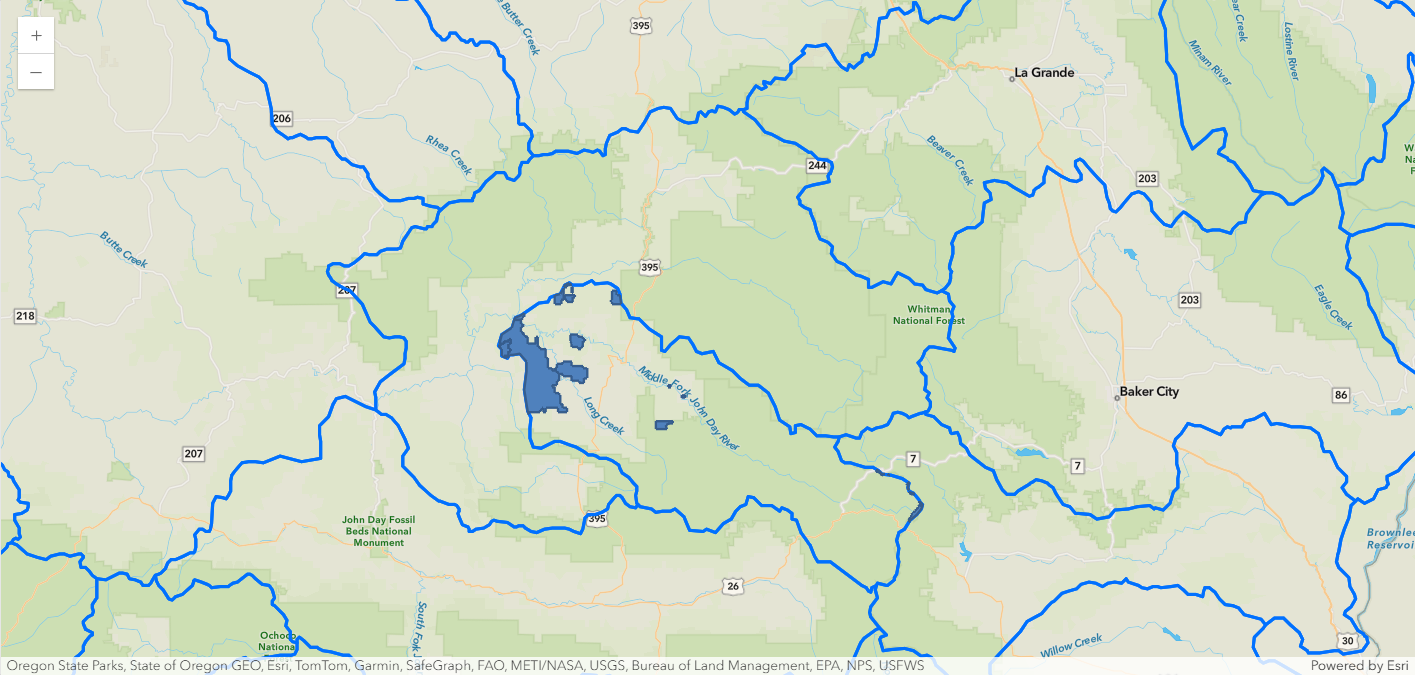

In [31]:
map4 = gis.map('oregon')
map4

<center>Grazing allotments are filtered by a particular hydrologic basin (Middle Fork John Day). The map shows all the allotments (or portions of allotments) that are in the basin, and the table above lists them with the associated information.</center>

In [32]:
map4.center = [44.88, -118.83]

In [33]:
map4.zoom = 8

In [34]:
map4.content.add(hydro_units)

In [35]:
john_day_df.spatial.plot(map_widget=map4)

True

### Display a particular grazing allotment to see which basins intersect it

We will filter grazing allotments using allotment number 04003.

In [36]:
allot_df = basin_overlay_df[basin_overlay_df['allot_no'] == '04003']

In [37]:
allot_df

,BASIN_NAME,allot_name,allot_no,REGION,HUC,SHAPE
512,NORTH FORK JOHN DAY,SLICKEAR MTN.,04003,17,17070202,"{""rings"": [[[-13276660.1969, 5581616.3978], [-..."
513,MIDDLE FORK JOHN DAY,SLICKEAR MTN.,04003,17,17070203,"{""rings"": [[[-13269794.5899, 5593722.8408], [-..."


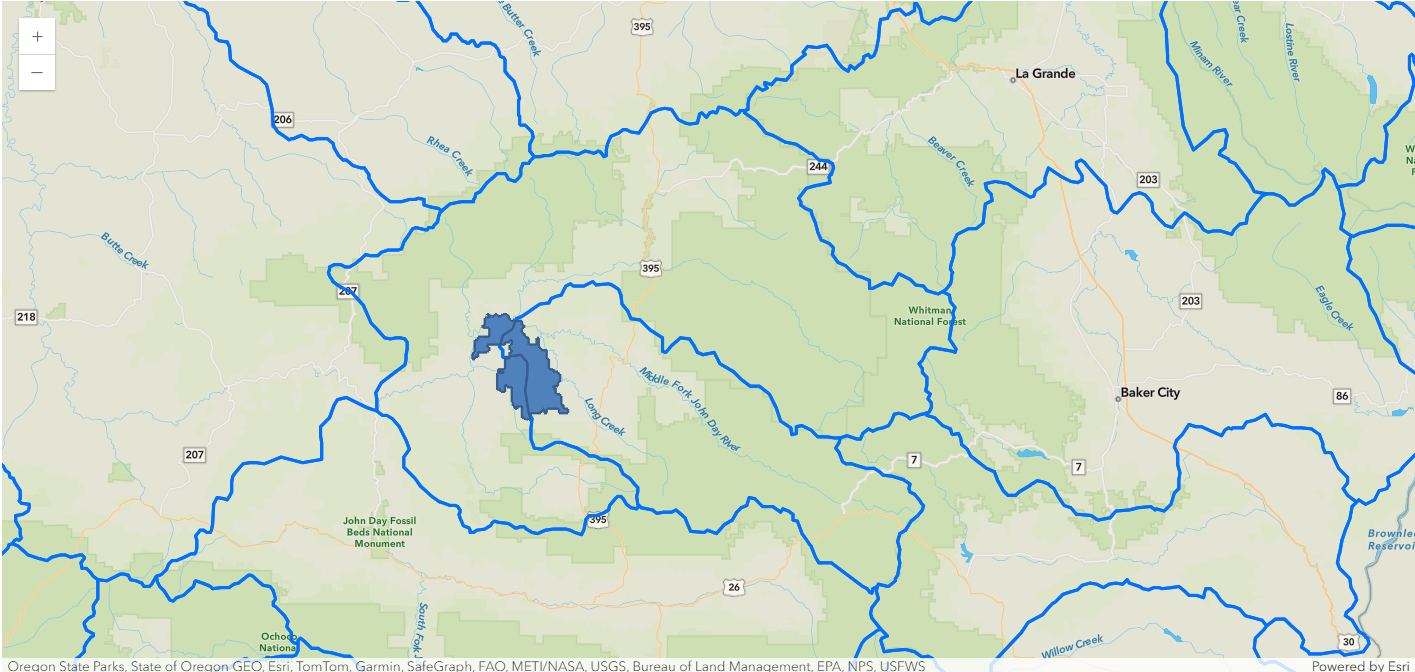

In [38]:
map5 = gis.map('Oregon')
map5

Grazing allotments are filtered using a particular allotment number (04003). The map shows in which basins the allotment is.

In [39]:
map5.zoom = 8

In [40]:
map5.center = [44.88, -118.83]

In [41]:
map5.content.add(hydro_units)

In [42]:
allot_df.spatial.plot(map_widget=map5)

True

### Assigning allotment information to streams


We will again use `overlay_layers` tool, this time overlaying streams with grazing allotments (area features can be overlaid with line or point features as well as other area features).

We will overlay streams with grazing allotments using the Intersect option. The output layer contains only those stream segments that cross a grazing allotment.

In [43]:
stream_overlay = overlay_layers(streams,
                                grazing_allotments,
                                overlay_type='Intersect',
                                output_name="StreamOverlay" + str(dt.now().microsecond)
                               )

{"cost": 5.97}


In [44]:
stream_overlay

<Item title:"StreamOverlay807080" type:Feature Layer Collection owner:arcgis_python>

Read the overlay layer as Spatially Enabled DataFrame.

### Mapping and exploring stream overlay results

In [45]:
stdf = pd.DataFrame.spatial.from_layer(stream_overlay.layers[0])

In [46]:
cols = ['allot_name', 'allot_no', 'HUC', 'PNAME', 'SHAPE' ]

In [47]:
stream_overlay_df = stdf[cols]

In [48]:
stream_overlay_df.head()

,allot_name,allot_no,HUC,PNAME,SHAPE
0,FERRY CANYON COMMON,07547,17070306,DESCHUTES R,"{""paths"": [[[-13455312.6361, 5686478.1643], [-..."
1,JOHNSON,07570,17070306,DESCHUTES R,"{""paths"": [[[-13459181.4415, 5708762.5207], [-..."
2,CLAUSEN,07507,17070306,DESCHUTES R,"{""paths"": [[[-13454247.8244, 5694318.6298], [-..."
3,HAMMEL LE,07532,17070306,DESCHUTES R,"{""paths"": [[[-13455033.5822, 5688216.154], [-1..."
4,HAMMEL EW,07533,17070306,DESCHUTES R,"{""paths"": [[[-13450887.4577, 5703034.2186], [-..."


In [49]:
st_grp = stream_overlay_df.groupby('PNAME').size()

<AxesSubplot: ylabel='PNAME'>

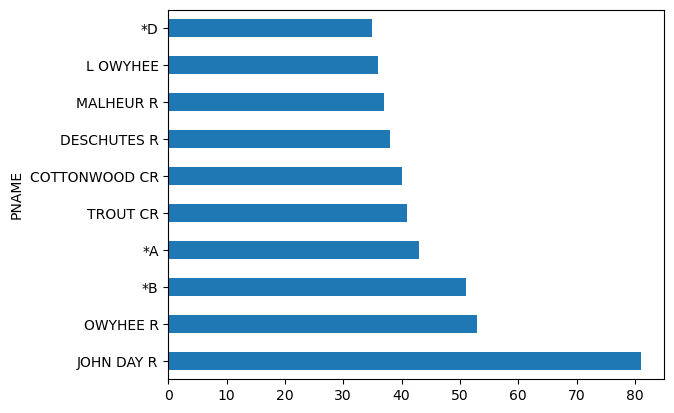

In [50]:
st_grp.nlargest(10).plot(kind='barh')

John Day River is the third longest free flowing river in contiguous US.
The plot shows that this river is mostly used for ranching.

In [51]:
stream_overlay_df.groupby('allot_name').size().nlargest(10)

allot_name
THREE FINGERS           36
JACKIES BUTTE SUMMER    23
QUARTZ MOUNTAIN         23
SADDLE BUTTE            23
SUMMIT PRAIRIE          22
WALLROCK                21
G.I.                    16
BIG BUTTE               15
BOARD CORRALS           15
COYOTE LAKE             14
dtype: int64

Thirty-six (36) stream segments from 17 different streams pass through the 'THREE FINGERS' grazing allotment.

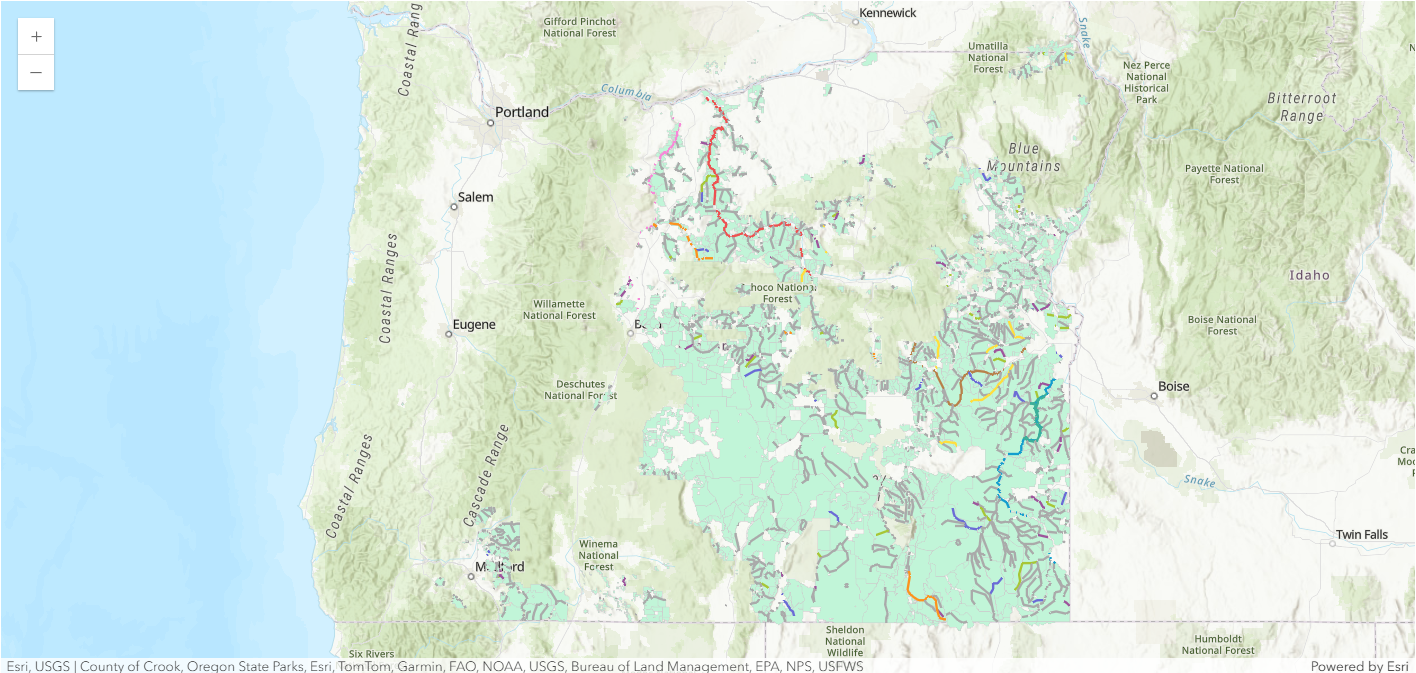

In [52]:
map6 = gis.map('oregon')
map6.basemap.basemap = 'topo-vector'
map6.content.add(grazing_allotments)
map6.content.add(stream_overlay_df)
map6

<center>Map of streams overlaid by grazing allotments.</center>

In [53]:
sm_manager = map6.content.renderer(1).smart_mapping()
sm_manager.unique_values_renderer(field="PNAME")

In [54]:
map6.zoom = 7

### Display a stream and grazing allotments it intersects

We will filter the analysis_layer for a specific stream—BRIDGE CR.

In [55]:
creek_df = stream_overlay_df[stream_overlay_df['PNAME'] == 'BRIDGE CR']

In [56]:
creek_df.head()

,allot_name,allot_no,HUC,PNAME,SHAPE
387,BUCK CREEK-BRIDGE CR,00702,17120005,BRIDGE CR,"{""paths"": [[[-13485835.5035, 5327100.6087], [-..."
388,UPPER BRIDGE CREEK,00701,17120005,BRIDGE CR,"{""paths"": [[[-13488884.9907, 5323673.5952], [-..."
809,BURNT RANCH,02624,17070204,BRIDGE CR,"{""paths"": [[[-13392864.8203, 5579859.7598], [-..."
810,SUTTON MTN.,02533,17070204,BRIDGE CR,"{""paths"": [[[-13392552.7024, 5577996.559], [-1..."
854,BANTAM,02515,17070204,BRIDGE CR,"{""paths"": [[[-13390882.7986, 5569434.5569], [-..."


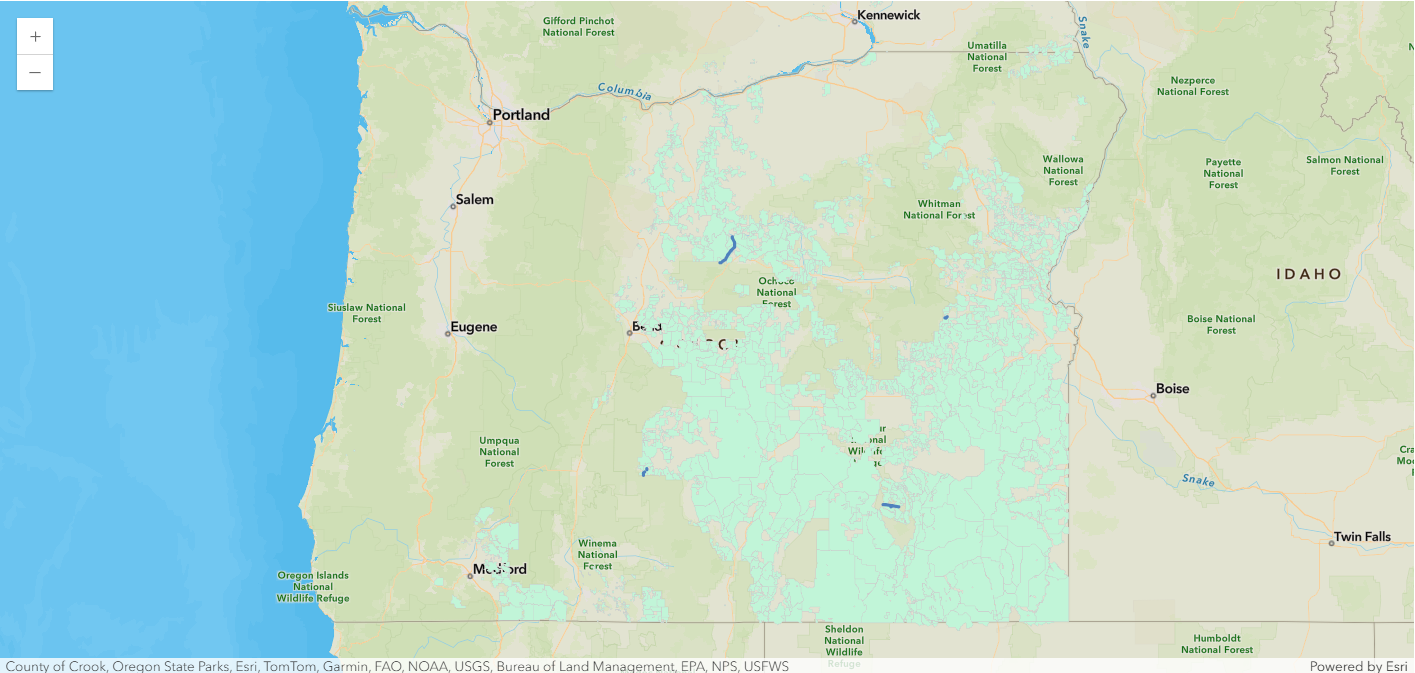

In [57]:
map7 = gis.map('oregon')
map7

This map shows in which allotment each stream segment falls.

In [58]:
map7.content.add(grazing_allotments)

In [59]:
creek_df.spatial.plot(map_widget=map7)

True

### Conclusion

Biologists can now identify which hydrologic basin and stream(s) intersect with which grazing allotments in an effort to identify sources of chronic water quality issues.